# Notebook 03 — Bulk Differential Expression Analysis
## GSE136666 — Substantia nigra: Parkinson vs Control

### Role in the 12-notebook project
This notebook performs the **formal differential-expression step** for the bulk RNA-seq discovery cohort.

### Primary question
Which genes show differential expression in substantia nigra from Parkinson's disease samples compared with controls?

### Statistical strategy
- **Primary model:** `~ disease`
- **Sensitivity model:** `~ sex + disease`
- **Primary contrast:** Parkinson vs Control
- **Multiple-testing correction:** Benjamini–Hochberg FDR
- **Primary inferential engine:** **PyDESeq2**
- **LFC shrinkage:** attempted with apeGLM via `lfc_shrink()` when available

### Important interpretation rules
1. Raw integer counts, not normalized/log counts, enter the negative-binomial model.
2. `padj < 0.05` defines statistical evidence after multiple-testing correction.
3. `|log2FC| >= 1` is an optional effect-size threshold, not a substitute for FDR.
4. The full ranked table is retained for Notebook 04 so that GSEA does not depend on an arbitrary DEG cutoff.
5. The original paper's reported number of DEGs is a **coherence benchmark**, never a target to reproduce.
6. Because sex is balanced within disease groups, `~ disease` remains the primary model; `~ sex + disease` tests robustness.

> If PyDESeq2 is unavailable, this notebook can generate an explicitly labeled **exploratory fallback ranking** from normalized log counts. That fallback is **not** considered the final inferential result and must not be used as the definitive DEG set for the thesis.

In [1]:
# 0. Imports and reproducibility
from pathlib import Path
import csv
import re
import json
import sys
import platform
import importlib.util
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind, spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list
from statsmodels.stats.multitest import multipletests

from IPython.display import display

RANDOM_STATE = 42
ALPHA = 0.05
EFFECT_CUTOFF = 1.0  # optional |log2FC| threshold

np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("PyDESeq2 installed:", importlib.util.find_spec("pydeseq2") is not None)

Python: 3.13.5
Platform: Linux-6.18.44-x86_64-with-glibc2.41
pandas: 2.2.3
numpy: 2.3.5
PyDESeq2 installed: False


## PyDESeq2 installation

Current PyDESeq2 releases require Python 3.12+.

If the next cell reports that PyDESeq2 is missing, install it in the environment used by Jupyter and restart the kernel:

```bash
pip install pydeseq2
```

or with conda:

```bash
conda install -c bioconda pydeseq2
```

The code below follows the current API based on `DeseqDataSet`, `DeseqStats`, Wald testing and `lfc_shrink`.

In [2]:
# 1. Project folders and flexible input discovery
PROJECT_ROOT = Path.cwd()

SEARCH_ROOTS = [
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    PROJECT_ROOT / "data",
    PROJECT_ROOT.parent / "data",
    Path("/mnt/data"),
]

RESULTS_DIR = PROJECT_ROOT / "results" / "differential_expression"
FIGURES_DIR = PROJECT_ROOT / "figures" / "differential_expression"
EXPORT_DIR = PROJECT_ROOT / "data" / "processed" / "notebook03"

for d in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def find_file(patterns):
    if isinstance(patterns, str):
        patterns = [patterns]
    matches = []
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for pattern in patterns:
            matches.extend(root.rglob(pattern))
    matches = sorted(set(p.resolve() for p in matches if p.is_file()))
    return matches[0] if matches else None

# Prefer Notebook 02 outputs; fall back to original files when necessary.
N02_COUNTS = find_file("GSE136666_SN_filtered_raw_counts.csv")
N02_META = find_file("GSE136666_SN_metadata.csv")
N02_NORM = find_file("GSE136666_SN_median_ratio_normalized_counts.csv")
N02_LOG = find_file("GSE136666_SN_log2_normalized_counts.csv")

RAW_COUNTS = find_file([
    "GSE136666_raw_counts_GRCh38.p13_NCBI*.tsv",
    "*GSE136666*raw_counts*.tsv",
])
SERIES_META = find_file([
    "GSE136666_series_matrix*.txt",
    "*GSE136666*series_matrix*.txt",
])

print("Notebook 02 filtered counts:", N02_COUNTS)
print("Notebook 02 metadata:", N02_META)
print("Original counts fallback:", RAW_COUNTS)
print("Series metadata fallback:", SERIES_META)

Notebook 02 filtered counts: None
Notebook 02 metadata: None
Original counts fallback: /mnt/data/GSE136666_raw_counts_GRCh38.p13_NCBI(1).tsv
Series metadata fallback: /mnt/data/GSE136666_series_matrix(1).txt


In [3]:
# 2. GEO metadata parser fallback
def parse_geo_series_matrix(path):
    raw_fields = {}
    characteristic_rows = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.startswith("!"):
                continue

            parts = next(csv.reader([line], delimiter="\t", quotechar='"'))
            key, values = parts[0], parts[1:]

            if key == "!Sample_characteristics_ch1":
                characteristic_rows.append(values)
            else:
                raw_fields.setdefault(key, []).append(values)

    titles = raw_fields["!Sample_title"][0]
    accessions = raw_fields["!Sample_geo_accession"][0]

    meta = pd.DataFrame({
        "sample_title": titles,
        "geo_accession": accessions,
    })

    for values in characteristic_rows:
        if len(values) != len(meta):
            continue

        prefixes, parsed = [], []
        for value in values:
            if ":" in value:
                k, v = value.split(":", 1)
                prefixes.append(k.strip().lower())
                parsed.append(v.strip())
            else:
                prefixes.append(None)
                parsed.append(value.strip())

        valid = [p for p in prefixes if p is not None]
        if valid and len(set(valid)) == 1:
            col = re.sub(r"[^a-z0-9]+", "_", valid[0]).strip("_")
            meta[col] = parsed

    if "gender" in meta:
        meta["sex"] = meta["gender"].str.upper().replace({
            "F": "Female",
            "M": "Male",
        })

    meta["disease"] = meta["disease_state"].replace({
        "Control": "Control",
        "Parkinson’s disease": "Parkinson",
        "Parkinson's disease": "Parkinson",
    })

    meta["tissue_clean"] = meta["tissue"].replace({
        "Substantia nigra": "Substantia_nigra",
        "Putamen": "Putamen",
    })

    return meta

In [4]:
# 3. Load Notebook 02 inputs or reconstruct them reproducibly
if N02_COUNTS is not None and N02_META is not None:
    print("Using validated Notebook 02 outputs.")
    sn_counts_filt = pd.read_csv(N02_COUNTS, index_col=0)
    sn_meta = pd.read_csv(N02_META)
else:
    print("Notebook 02 outputs not found — reconstructing the same SN subset and filter.")
    assert RAW_COUNTS is not None and SERIES_META is not None

    raw = pd.read_csv(RAW_COUNTS, sep="\t")
    counts_all = raw.set_index("GeneID")
    meta = parse_geo_series_matrix(SERIES_META)

    assert set(counts_all.columns) == set(meta["geo_accession"])

    meta = (
        meta.set_index("geo_accession")
        .loc[counts_all.columns]
        .reset_index(names="geo_accession")
    )

    sn_meta = meta.loc[meta["tissue_clean"] == "Substantia_nigra"].copy()
    sn_ids = sn_meta["geo_accession"].tolist()
    sn_counts = counts_all[sn_ids].copy()

    # Same rule selected in Notebook 02:
    # count >= 10 in at least 3 SN libraries.
    keep_mask = (sn_counts >= 10).sum(axis=1) >= 3
    sn_counts_filt = sn_counts.loc[keep_mask].copy()

# Standardize GeneID representation.
sn_counts_filt.index = sn_counts_filt.index.astype(str)

# Align sample order exactly.
sample_ids = sn_meta["geo_accession"].tolist()
assert set(sample_ids) == set(sn_counts_filt.columns)
sn_counts_filt = sn_counts_filt[sample_ids]

print("Filtered count matrix:", sn_counts_filt.shape)
print("Disease balance:")
display(sn_meta["disease"].value_counts())
print("Sex × disease:")
display(pd.crosstab(sn_meta["sex"], sn_meta["disease"]))

assert sn_counts_filt.shape[1] == 10
assert sn_meta["disease"].value_counts().to_dict() == {"Control": 5, "Parkinson": 5}
assert (sn_counts_filt >= 0).all().all()
assert np.allclose(sn_counts_filt.to_numpy(), np.round(sn_counts_filt.to_numpy()))

Notebook 02 outputs not found — reconstructing the same SN subset and filter.
Filtered count matrix: (22369, 10)
Disease balance:


disease
Control      5
Parkinson    5
Name: count, dtype: int64

Sex × disease:


disease,Control,Parkinson
sex,,
Female,2,2
Male,3,3


In [5]:
# 4. Recreate Notebook 02 normalization if normalized files are unavailable
def deseq2_median_ratio_size_factors(counts_genes_by_samples):
    X = counts_genes_by_samples.astype(float)
    positive_all = (X > 0).all(axis=1)
    ref = X.loc[positive_all]

    if ref.empty:
        raise ValueError("No genes are positive in all samples.")

    geom_means = np.exp(np.log(ref).mean(axis=1))
    ratios = ref.div(geom_means, axis=0)
    sf = ratios.median(axis=0)
    sf = sf / np.exp(np.log(sf).mean())

    return sf

if N02_NORM is not None:
    normalized_counts = pd.read_csv(N02_NORM, index_col=0)
    normalized_counts.index = normalized_counts.index.astype(str)
    normalized_counts = normalized_counts.loc[sn_counts_filt.index, sample_ids]
else:
    size_factors_qc = deseq2_median_ratio_size_factors(sn_counts_filt)
    normalized_counts = sn_counts_filt.div(size_factors_qc, axis=1)

if N02_LOG is not None:
    log_norm = pd.read_csv(N02_LOG, index_col=0)
    log_norm.index = log_norm.index.astype(str)
    log_norm = log_norm.loc[sn_counts_filt.index, sample_ids]
else:
    log_norm = np.log2(normalized_counts + 1)

print("Normalized matrix:", normalized_counts.shape)
print("Log-QC matrix:", log_norm.shape)

Normalized matrix: (22369, 10)
Log-QC matrix: (22369, 10)


# Part A — Formal PyDESeq2 inference

The following section is the **primary analysis**.

PyDESeq2 expects:
- rows = samples
- columns = genes
- raw integer counts
- metadata indexed by the same sample IDs

We explicitly set category reference levels so that positive log2 fold change means:

> **higher expression in Parkinson compared with Control**

In [6]:
# 5. Prepare counts and metadata for PyDESeq2
counts_deseq = sn_counts_filt.T.astype(int)

model_meta = (
    sn_meta
    .set_index("geo_accession")
    .loc[counts_deseq.index, ["disease", "sex"]]
    .copy()
)

model_meta["disease"] = pd.Categorical(
    model_meta["disease"],
    categories=["Control", "Parkinson"],
    ordered=False,
)

model_meta["sex"] = pd.Categorical(
    model_meta["sex"],
    categories=["Female", "Male"],
    ordered=False,
)

print("Counts orientation for PyDESeq2:", counts_deseq.shape, "(samples × genes)")
display(model_meta)

Counts orientation for PyDESeq2: (10, 22369) (samples × genes)


,disease,sex
GSM4054763,Control,Female
GSM4054764,Control,Female
GSM4054765,Control,Male
GSM4054766,Control,Male
GSM4054767,Control,Male
GSM4054768,Parkinson,Female
GSM4054769,Parkinson,Female
GSM4054770,Parkinson,Male
GSM4054771,Parkinson,Male
GSM4054772,Parkinson,Male


In [7]:
# 6. Detect PyDESeq2
HAS_PYDESEQ2 = importlib.util.find_spec("pydeseq2") is not None

if HAS_PYDESEQ2:
    import pydeseq2
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats

    print("PyDESeq2 version:", getattr(pydeseq2, "__version__", "unknown"))
else:
    print("PyDESeq2 is NOT installed.")
    print("The formal DESeq2-style inference cells will be skipped.")
    print("Install with: pip install pydeseq2")

PyDESeq2 is NOT installed.
The formal DESeq2-style inference cells will be skipped.
Install with: pip install pydeseq2


In [8]:
# 7. Primary model: ~ disease
primary_results = None
primary_results_shrunk = None
dds_primary = None
stats_primary = None

if HAS_PYDESEQ2:
    dds_primary = DeseqDataSet(
        counts=counts_deseq,
        metadata=model_meta,
        design="~ disease",
        refit_cooks=True,
        n_cpus=1,
        quiet=False,
    )

    dds_primary.deseq2()

    stats_primary = DeseqStats(
        dds_primary,
        contrast=["disease", "Parkinson", "Control"],
        alpha=ALPHA,
        n_cpus=1,
        quiet=False,
    )

    stats_primary.summary()

    primary_results = stats_primary.results_df.copy()
    primary_results.index = primary_results.index.astype(str)
    primary_results.index.name = "GeneID"

    print("Primary model complete:", primary_results.shape)
    display(primary_results.sort_values("padj").head(20))
else:
    print("Skipped: PyDESeq2 unavailable.")

Skipped: PyDESeq2 unavailable.


In [9]:
# 8. Primary-model LFC shrinkage
if HAS_PYDESEQ2 and stats_primary is not None:
    try:
        stats_primary.lfc_shrink(coeff="disease[T.Parkinson]")
        primary_results_shrunk = stats_primary.results_df.copy()
        primary_results_shrunk.index = primary_results_shrunk.index.astype(str)
        primary_results_shrunk.index.name = "GeneID"

        print("LFC shrinkage completed.")
        display(primary_results_shrunk.sort_values("padj").head(20))
    except Exception as exc:
        warnings.warn(
            "LFC shrinkage could not be completed. "
            f"Unshrunk PyDESeq2 estimates remain available. Details: {exc}"
        )
        primary_results_shrunk = None
else:
    print("Shrinkage skipped.")

Shrinkage skipped.


In [10]:
# 9. Sensitivity model: ~ sex + disease
sensitivity_results = None
sensitivity_results_shrunk = None
dds_sensitivity = None
stats_sensitivity = None

if HAS_PYDESEQ2:
    dds_sensitivity = DeseqDataSet(
        counts=counts_deseq,
        metadata=model_meta,
        design="~ sex + disease",
        refit_cooks=True,
        n_cpus=1,
        quiet=False,
    )

    dds_sensitivity.deseq2()

    stats_sensitivity = DeseqStats(
        dds_sensitivity,
        contrast=["disease", "Parkinson", "Control"],
        alpha=ALPHA,
        n_cpus=1,
        quiet=False,
    )

    stats_sensitivity.summary()

    sensitivity_results = stats_sensitivity.results_df.copy()
    sensitivity_results.index = sensitivity_results.index.astype(str)
    sensitivity_results.index.name = "GeneID"

    try:
        stats_sensitivity.lfc_shrink(coeff="disease[T.Parkinson]")
        sensitivity_results_shrunk = stats_sensitivity.results_df.copy()
        sensitivity_results_shrunk.index = sensitivity_results_shrunk.index.astype(str)
        sensitivity_results_shrunk.index.name = "GeneID"
    except Exception as exc:
        warnings.warn(f"Sensitivity-model shrinkage failed: {exc}")

    print("Sensitivity model complete:", sensitivity_results.shape)
    display(sensitivity_results.sort_values("padj").head(20))
else:
    print("Skipped: PyDESeq2 unavailable.")

Skipped: PyDESeq2 unavailable.


# Part B — Explicitly labeled exploratory fallback

This section exists only so the notebook can still be inspected when PyDESeq2 is unavailable.

It uses:
- Notebook 02 median-ratio normalized counts
- `log2(normalized count + 1)`
- Welch's two-sample t-test
- Benjamini–Hochberg FDR
- a descriptive log2 ratio of group mean normalized counts

**This is not mathematically equivalent to the negative-binomial DESeq2 model.**  
Do not use fallback `padj` values as the definitive thesis DEG results.

In [11]:
# 10. Exploratory fallback ranking — vectorized for speed
control_ids = model_meta.index[model_meta["disease"] == "Control"].tolist()
pd_ids = model_meta.index[model_meta["disease"] == "Parkinson"].tolist()

control_log = log_norm[control_ids].to_numpy(dtype=float)
pd_log = log_norm[pd_ids].to_numpy(dtype=float)

# Welch t-test across genes in one vectorized operation.
stat, pvalue = ttest_ind(
    pd_log,
    control_log,
    axis=1,
    equal_var=False,
    nan_policy="omit",
)

control_mean_norm = normalized_counts[control_ids].mean(axis=1).to_numpy(dtype=float)
pd_mean_norm = normalized_counts[pd_ids].mean(axis=1).to_numpy(dtype=float)

descriptive_lfc = np.log2(
    (pd_mean_norm + 0.5) / (control_mean_norm + 0.5)
)

fallback_results = pd.DataFrame({
    "GeneID": log_norm.index.astype(str),
    "baseMean_approx": normalized_counts.mean(axis=1).to_numpy(dtype=float),
    "log2FoldChange_approx": descriptive_lfc,
    "welch_stat": stat,
    "pvalue_exploratory": pvalue,
}).set_index("GeneID")

valid_p = fallback_results["pvalue_exploratory"].notna()
fallback_results["padj_exploratory"] = np.nan

if valid_p.any():
    fallback_results.loc[valid_p, "padj_exploratory"] = multipletests(
        fallback_results.loc[valid_p, "pvalue_exploratory"],
        method="fdr_bh",
    )[1]

fallback_results["significant_exploratory"] = (
    fallback_results["padj_exploratory"] < ALPHA
)

fallback_results["significant_and_large_exploratory"] = (
    (fallback_results["padj_exploratory"] < ALPHA)
    & (fallback_results["log2FoldChange_approx"].abs() >= EFFECT_CUTOFF)
)

display(
    fallback_results
    .sort_values("padj_exploratory")
    .head(20)
)

,baseMean_approx,log2FoldChange_approx,welch_stat,pvalue_exploratory,padj_exploratory,significant_exploratory,significant_and_large_exploratory
GeneID,,,,,,,
55052,1199.730721,-0.306252,-4.839148,0.001307,0.407208,False,False
90835,125.601189,-0.444458,-4.454046,0.003619,0.407208,False,False
262,3837.878401,0.347631,4.971235,0.001363,0.407208,False,False
91749,182.204697,0.592494,4.586381,0.001797,0.407208,False,False
5261,607.548633,-0.255438,-4.075809,0.003641,0.407208,False,False
8898,2042.337518,0.368015,4.992754,0.001329,0.407208,False,False
143686,2895.333097,0.395837,4.694129,0.003013,0.407208,False,False
100422985,18.037876,-0.363518,-5.690492,0.002912,0.407208,False,False
4830,983.919705,-0.620474,-4.743011,0.001885,0.407208,False,False


In [12]:
# 11. Select the authoritative result table for visualization/export
if primary_results is not None:
    primary_for_reporting = (
        primary_results_shrunk.copy()
        if primary_results_shrunk is not None
        else primary_results.copy()
    )
    RESULT_MODE = "PyDESeq2"
else:
    primary_for_reporting = fallback_results.rename(columns={
        "baseMean_approx": "baseMean",
        "log2FoldChange_approx": "log2FoldChange",
        "pvalue_exploratory": "pvalue",
        "padj_exploratory": "padj",
    }).copy()
    RESULT_MODE = "EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE"

print("Current reporting mode:", RESULT_MODE)

primary_for_reporting["significant_fdr"] = (
    primary_for_reporting["padj"] < ALPHA
)

primary_for_reporting["significant_fdr_and_effect"] = (
    (primary_for_reporting["padj"] < ALPHA)
    & (primary_for_reporting["log2FoldChange"].abs() >= EFFECT_CUTOFF)
)

primary_for_reporting["direction"] = np.select(
    [
        primary_for_reporting["significant_fdr_and_effect"]
        & (primary_for_reporting["log2FoldChange"] > 0),

        primary_for_reporting["significant_fdr_and_effect"]
        & (primary_for_reporting["log2FoldChange"] < 0),
    ],
    ["Up_in_Parkinson", "Down_in_Parkinson"],
    default="Not_significant_or_small",
)

summary_counts = pd.Series({
    "tested_genes": int(len(primary_for_reporting)),
    "FDR_lt_0.05": int(primary_for_reporting["significant_fdr"].sum()),
    "FDR_lt_0.05_and_abs_LFC_ge_1": int(primary_for_reporting["significant_fdr_and_effect"].sum()),
    "up_in_Parkinson": int((primary_for_reporting["direction"] == "Up_in_Parkinson").sum()),
    "down_in_Parkinson": int((primary_for_reporting["direction"] == "Down_in_Parkinson").sum()),
})

display(summary_counts)

Current reporting mode: EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE


tested_genes                    22369
FDR_lt_0.05                         0
FDR_lt_0.05_and_abs_LFC_ge_1        0
up_in_Parkinson                     0
down_in_Parkinson                   0
dtype: int64

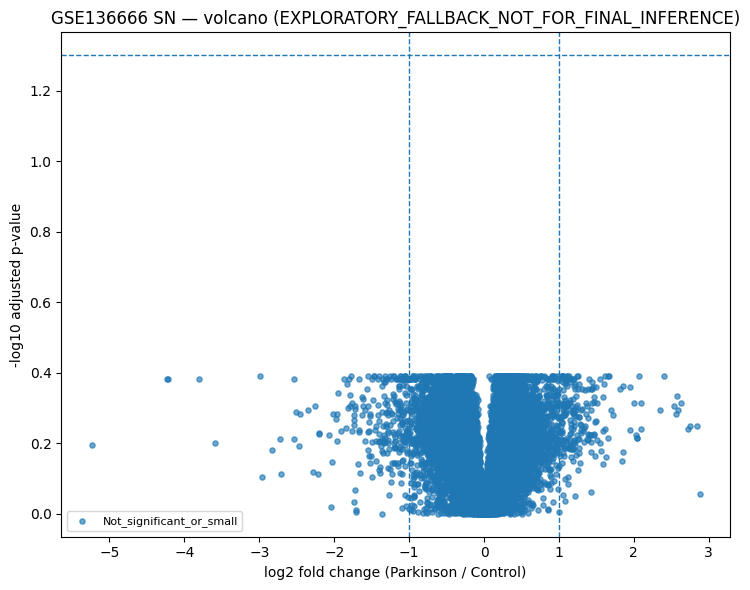

In [13]:
# 12. Volcano plot
plot_df = primary_for_reporting.copy()

plot_df["minus_log10_padj"] = -np.log10(
    plot_df["padj"].clip(lower=np.nextafter(0, 1))
)

finite_mask = np.isfinite(plot_df["log2FoldChange"]) & np.isfinite(plot_df["minus_log10_padj"])
v = plot_df.loc[finite_mask].copy()

fig, ax = plt.subplots(figsize=(7.5, 6))

for label, sub in v.groupby("direction"):
    ax.scatter(
        sub["log2FoldChange"],
        sub["minus_log10_padj"],
        s=14,
        alpha=0.65,
        label=label,
    )

ax.axvline(EFFECT_CUTOFF, linewidth=1, linestyle="--")
ax.axvline(-EFFECT_CUTOFF, linewidth=1, linestyle="--")
ax.axhline(-np.log10(ALPHA), linewidth=1, linestyle="--")

ax.set_xlabel("log2 fold change (Parkinson / Control)")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title(f"GSE136666 SN — volcano ({RESULT_MODE})")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE136666_SN_volcano.png", dpi=300, bbox_inches="tight")
plt.show()

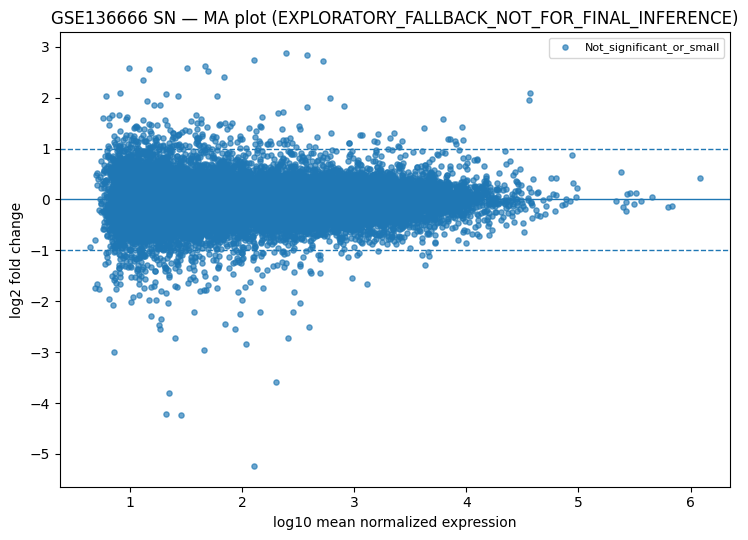

In [14]:
# 13. MA plot
ma_df = primary_for_reporting.copy()

valid = (
    np.isfinite(ma_df["baseMean"])
    & np.isfinite(ma_df["log2FoldChange"])
    & (ma_df["baseMean"] > 0)
)

m = ma_df.loc[valid].copy()

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for label, sub in m.groupby("direction"):
    ax.scatter(
        np.log10(sub["baseMean"]),
        sub["log2FoldChange"],
        s=14,
        alpha=0.65,
        label=label,
    )

ax.axhline(0, linewidth=1)
ax.axhline(EFFECT_CUTOFF, linewidth=1, linestyle="--")
ax.axhline(-EFFECT_CUTOFF, linewidth=1, linestyle="--")

ax.set_xlabel("log10 mean normalized expression")
ax.set_ylabel("log2 fold change")
ax.set_title(f"GSE136666 SN — MA plot ({RESULT_MODE})")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE136666_SN_MA_plot.png", dpi=300, bbox_inches="tight")
plt.show()

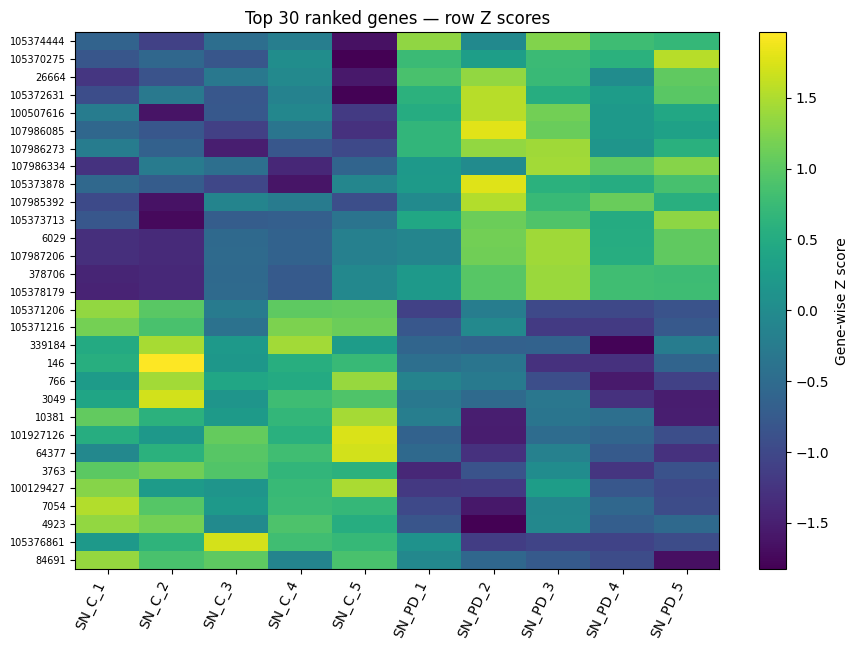

In [15]:
# 14. Heatmap of top-ranked genes
# Ranking uses adjusted p-value first and |LFC| second.
heat_rank = (
    primary_for_reporting
    .dropna(subset=["padj", "log2FoldChange"])
    .assign(abs_lfc=lambda x: x["log2FoldChange"].abs())
    .sort_values(["padj", "abs_lfc"], ascending=[True, False])
)

N_HEAT = min(30, len(heat_rank))
top_heat_genes = heat_rank.head(N_HEAT).index.intersection(log_norm.index)

heat = log_norm.loc[top_heat_genes, sample_ids].copy()

# Z-score each gene for visualization only.
heat_z = heat.sub(heat.mean(axis=1), axis=0)
sd = heat.std(axis=1).replace(0, np.nan)
heat_z = heat_z.div(sd, axis=0).fillna(0)

# Cluster genes; preserve metadata/sample order by disease.
sample_order = (
    sn_meta
    .sort_values(["disease", "sex", "sample_title"])
    ["geo_accession"]
    .tolist()
)

if len(heat_z) >= 2:
    gene_linkage = linkage(heat_z[sample_order], method="average", metric="euclidean")
    gene_order = heat_z.index[leaves_list(gene_linkage)]
else:
    gene_order = heat_z.index

plot_heat = heat_z.loc[gene_order, sample_order]

fig, ax = plt.subplots(figsize=(9, max(5, len(plot_heat) * 0.22)))
im = ax.imshow(plot_heat.values, aspect="auto")

sample_labels = (
    sn_meta.set_index("geo_accession")
    .loc[sample_order, "sample_title"]
    .tolist()
)

ax.set_xticks(range(len(sample_labels)))
ax.set_xticklabels(sample_labels, rotation=65, ha="right")
ax.set_yticks(range(len(plot_heat)))
ax.set_yticklabels(plot_heat.index.astype(str), fontsize=7)

ax.set_title(f"Top {len(plot_heat)} ranked genes — row Z scores")
fig.colorbar(im, ax=ax, label="Gene-wise Z score")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "GSE136666_SN_top_genes_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Part C — Primary vs sex-adjusted model robustness

This comparison is only inferentially valid when PyDESeq2 successfully ran both models.

Questions:
- Are log2 fold changes highly correlated?
- Do the same genes remain significant?
- Does adjusting for sex materially change direction or effect size?

In [16]:
# 15. Compare primary and sensitivity models
model_comparison = None

if primary_results is not None and sensitivity_results is not None:
    ptab = (
        primary_results_shrunk.copy()
        if primary_results_shrunk is not None
        else primary_results.copy()
    )

    stab = (
        sensitivity_results_shrunk.copy()
        if sensitivity_results_shrunk is not None
        else sensitivity_results.copy()
    )

    ptab = ptab.add_suffix("_primary")
    stab = stab.add_suffix("_sex_adjusted")

    model_comparison = ptab.join(stab, how="inner")

    valid = (
        model_comparison["log2FoldChange_primary"].notna()
        & model_comparison["log2FoldChange_sex_adjusted"].notna()
    )

    rho, rho_p = spearmanr(
        model_comparison.loc[valid, "log2FoldChange_primary"],
        model_comparison.loc[valid, "log2FoldChange_sex_adjusted"],
    )

    sig_primary = model_comparison["padj_primary"] < ALPHA
    sig_adjusted = model_comparison["padj_sex_adjusted"] < ALPHA

    robustness_summary = pd.Series({
        "genes_compared": int(valid.sum()),
        "LFC_Spearman_rho": float(rho),
        "LFC_Spearman_p": float(rho_p),
        "significant_primary": int(sig_primary.sum()),
        "significant_sex_adjusted": int(sig_adjusted.sum()),
        "significant_in_both": int((sig_primary & sig_adjusted).sum()),
        "primary_only": int((sig_primary & ~sig_adjusted).sum()),
        "sex_adjusted_only": int((~sig_primary & sig_adjusted).sum()),
    })

    display(robustness_summary)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(
        model_comparison.loc[valid, "log2FoldChange_primary"],
        model_comparison.loc[valid, "log2FoldChange_sex_adjusted"],
        s=12,
        alpha=0.5,
    )
    lo = np.nanpercentile(
        np.concatenate([
            model_comparison.loc[valid, "log2FoldChange_primary"].to_numpy(),
            model_comparison.loc[valid, "log2FoldChange_sex_adjusted"].to_numpy(),
        ]),
        1,
    )
    hi = np.nanpercentile(
        np.concatenate([
            model_comparison.loc[valid, "log2FoldChange_primary"].to_numpy(),
            model_comparison.loc[valid, "log2FoldChange_sex_adjusted"].to_numpy(),
        ]),
        99,
    )

    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Primary model log2FC: ~ disease")
    ax.set_ylabel("Sex-adjusted log2FC: ~ sex + disease")
    ax.set_title(f"Model robustness — Spearman ρ={rho:.3f}")

    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "GSE136666_SN_model_LFC_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    robustness_summary = pd.Series({
        "status": "Not available because PyDESeq2 did not run both models."
    })
    display(robustness_summary)

status    Not available because PyDESeq2 did not run bot...
dtype: object

In [17]:
# 16. Directional concordance among strongest effects
if model_comparison is not None:
    comp = model_comparison.copy()

    comp["same_direction"] = (
        np.sign(comp["log2FoldChange_primary"])
        == np.sign(comp["log2FoldChange_sex_adjusted"])
    )

    comp["absolute_LFC_difference"] = (
        comp["log2FoldChange_primary"]
        - comp["log2FoldChange_sex_adjusted"]
    ).abs()

    strongest = (
        comp
        .assign(abs_primary=lambda x: x["log2FoldChange_primary"].abs())
        .sort_values("abs_primary", ascending=False)
        .head(100)
    )

    print(
        "Same direction among 100 largest primary-model effects:",
        f"{strongest['same_direction'].mean():.1%}",
    )

    display(
        strongest[
            [
                "log2FoldChange_primary",
                "padj_primary",
                "log2FoldChange_sex_adjusted",
                "padj_sex_adjusted",
                "same_direction",
                "absolute_LFC_difference",
            ]
        ].head(20)
    )
else:
    print("Directional model comparison unavailable.")

Directional model comparison unavailable.


# Part D — DEG summaries and ranked output for Notebook 04

We export three conceptually different objects:

1. **Full result table** — all tested genes; primary object for reproducibility.
2. **FDR-significant genes** — statistical evidence only.
3. **FDR + effect-size genes** — stricter descriptive subset useful for heatmaps/networks.

For pathway analysis, Notebook 04 should primarily use a **ranked statistic over all genes**, not only the thresholded DEG subset.

In [18]:
# 17. Build DEG tables
full_results = primary_for_reporting.copy()

deg_fdr = full_results.loc[
    full_results["padj"] < ALPHA
].sort_values(["padj", "log2FoldChange"], ascending=[True, False])

deg_fdr_effect = full_results.loc[
    (full_results["padj"] < ALPHA)
    & (full_results["log2FoldChange"].abs() >= EFFECT_CUTOFF)
].sort_values(["padj", "log2FoldChange"], ascending=[True, False])

up_genes = deg_fdr_effect.loc[
    deg_fdr_effect["log2FoldChange"] > 0
]

down_genes = deg_fdr_effect.loc[
    deg_fdr_effect["log2FoldChange"] < 0
]

print("Full tested set:", len(full_results))
print("FDR < 0.05:", len(deg_fdr))
print("FDR < 0.05 + |log2FC| >= 1:", len(deg_fdr_effect))
print("Up in Parkinson:", len(up_genes))
print("Down in Parkinson:", len(down_genes))

display(deg_fdr_effect.head(30))

Full tested set: 22369
FDR < 0.05: 0
FDR < 0.05 + |log2FC| >= 1: 0
Up in Parkinson: 0
Down in Parkinson: 0


,baseMean,log2FoldChange,welch_stat,pvalue,padj,significant_exploratory,significant_and_large_exploratory,significant_fdr,significant_fdr_and_effect,direction
GeneID,,,,,,,,,,


In [19]:
# 18. Create ranked statistics for Notebook 04
# Prefer the Wald statistic from PyDESeq2 because it combines direction and evidence.
# If unavailable, use the exploratory Welch statistic and label it accordingly.

if RESULT_MODE == "PyDESeq2" and "stat" in full_results.columns:
    ranking = full_results[["stat"]].copy()
    ranking = ranking.rename(columns={"stat": "ranking_statistic"})
    ranking_method = "PyDESeq2 Wald statistic"
else:
    ranking = fallback_results[["welch_stat"]].copy()
    ranking = ranking.rename(columns={"welch_stat": "ranking_statistic"})
    ranking_method = "EXPLORATORY Welch statistic — replace after PyDESeq2 run"

ranking = (
    ranking
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values("ranking_statistic", ascending=False)
)

print("Ranking method:", ranking_method)
print("Genes in ranked list:", len(ranking))
display(ranking.head(15))
display(ranking.tail(15))

Ranking method: EXPLORATORY Welch statistic — replace after PyDESeq2 run
Genes in ranked list: 22369


,ranking_statistic
GeneID,
23235,7.539118
728024,7.156699
25800,6.734967
7771,6.679155
339287,6.647825
9738,6.266094
57474,6.244503
7716,6.235622
4204,6.193290


,ranking_statistic
GeneID,
100422985,-5.690492
102724788,-5.691570
2170,-5.750175
196294,-5.823673
347733,-5.940433
8263,-5.989956
7919,-6.204329
662,-6.250399
286122,-6.422282


In [20]:
# 19. Compare with literature benchmark WITHOUT targeting an exact number
# The previously established study summary reports 354 DEGs in substantia nigra.
# Different preprocessing, versions, filtering and modeling can change the exact count.

ORIGINAL_PAPER_SN_DEG_COUNT = 354

benchmark = pd.Series({
    "original_reported_SN_DEGs": ORIGINAL_PAPER_SN_DEG_COUNT,
    "current_FDR_lt_0.05": int((full_results["padj"] < ALPHA).sum()),
    "current_FDR_and_abs_LFC_ge_1": int(
        (
            (full_results["padj"] < ALPHA)
            & (full_results["log2FoldChange"].abs() >= EFFECT_CUTOFF)
        ).sum()
    ),
    "analysis_mode": RESULT_MODE,
})

display(benchmark)

if RESULT_MODE != "PyDESeq2":
    print(
        "IMPORTANT: comparison is provisional because the current run used "
        "the exploratory fallback rather than PyDESeq2."
    )

original_reported_SN_DEGs                                                354
current_FDR_lt_0.05                                                        0
current_FDR_and_abs_LFC_ge_1                                               0
analysis_mode                   EXPLORATORY_FALLBACK_NOT_FOR_FINAL_INFERENCE
dtype: object

IMPORTANT: comparison is provisional because the current run used the exploratory fallback rather than PyDESeq2.


In [21]:
# 20. Export all Notebook 03 outputs
full_results.to_csv(
    EXPORT_DIR / "GSE136666_SN_DE_full_results.csv"
)

deg_fdr.to_csv(
    EXPORT_DIR / "GSE136666_SN_DE_FDR_lt_0.05.csv"
)

deg_fdr_effect.to_csv(
    EXPORT_DIR / "GSE136666_SN_DE_FDR_lt_0.05_absLFC_ge_1.csv"
)

up_genes.to_csv(
    EXPORT_DIR / "GSE136666_SN_DE_up_in_Parkinson.csv"
)

down_genes.to_csv(
    EXPORT_DIR / "GSE136666_SN_DE_down_in_Parkinson.csv"
)

ranking.to_csv(
    EXPORT_DIR / "GSE136666_SN_ranked_statistic_for_GSEA.csv"
)

fallback_results.to_csv(
    RESULTS_DIR / "GSE136666_SN_exploratory_fallback_statistics.csv"
)

if primary_results is not None:
    primary_results.to_csv(
        RESULTS_DIR / "GSE136666_SN_PyDESeq2_primary_unshrunk.csv"
    )

if primary_results_shrunk is not None:
    primary_results_shrunk.to_csv(
        RESULTS_DIR / "GSE136666_SN_PyDESeq2_primary_shrunk.csv"
    )

if sensitivity_results is not None:
    sensitivity_results.to_csv(
        RESULTS_DIR / "GSE136666_SN_PyDESeq2_sex_adjusted_unshrunk.csv"
    )

if sensitivity_results_shrunk is not None:
    sensitivity_results_shrunk.to_csv(
        RESULTS_DIR / "GSE136666_SN_PyDESeq2_sex_adjusted_shrunk.csv"
    )

if model_comparison is not None:
    model_comparison.to_csv(
        RESULTS_DIR / "GSE136666_SN_primary_vs_sex_adjusted.csv"
    )

summary_counts.to_csv(
    RESULTS_DIR / "GSE136666_SN_DE_summary_counts.csv",
    header=["value"],
)

benchmark.to_csv(
    RESULTS_DIR / "GSE136666_SN_DE_benchmark_comparison.csv",
    header=["value"],
)

manifest = {
    "dataset": "GSE136666",
    "tissue": "Substantia nigra",
    "contrast": "Parkinson vs Control",
    "n_samples": int(sn_counts_filt.shape[1]),
    "n_genes_tested": int(len(full_results)),
    "filter_rule_from_notebook02": "count >= 10 in at least 3 SN libraries",
    "primary_design": "~ disease",
    "sensitivity_design": "~ sex + disease",
    "alpha": ALPHA,
    "effect_cutoff_abs_log2FC": EFFECT_CUTOFF,
    "result_mode": RESULT_MODE,
    "ranking_method": ranking_method,
    "next_notebook": "04_functional_metabolic_enrichment.ipynb",
}

with open(
    EXPORT_DIR / "notebook03_manifest.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("Exports:", EXPORT_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())
print("Figures:", FIGURES_DIR.resolve())

Exports: /mnt/data/data/processed/notebook03
Results: /mnt/data/results/differential_expression
Figures: /mnt/data/figures/differential_expression


In [22]:
# 21. Final reproducibility checkpoint
checks = {
    "10 SN samples": sn_counts_filt.shape[1] == 10,
    "5 Control + 5 Parkinson": model_meta["disease"].value_counts().to_dict() == {
        "Control": 5,
        "Parkinson": 5,
    },
    "Raw counts are integer-valued": bool(
        np.allclose(
            counts_deseq.to_numpy(),
            np.round(counts_deseq.to_numpy()),
        )
    ),
    "All tested genes exported": len(full_results) == sn_counts_filt.shape[0],
    "Ranking is non-empty": len(ranking) > 0,
    "No duplicate GeneIDs in full results": not full_results.index.duplicated().any(),
}

checkpoint = pd.Series(checks, name="passed")
display(checkpoint)

assert checkpoint.all(), "Notebook 03 structural checkpoint failed."

if RESULT_MODE == "PyDESeq2":
    print("\n✓ Notebook 03 passed with formal PyDESeq2 inference.")
    print("The ranked Wald statistic is ready for Notebook 04.")
else:
    print("\n⚠ Notebook 03 structure passed, but formal PyDESeq2 inference was NOT executed.")
    print("Install PyDESeq2 and rerun before treating the DEG results as final.")

10 SN samples                           True
5 Control + 5 Parkinson                 True
Raw counts are integer-valued           True
All tested genes exported               True
Ranking is non-empty                    True
No duplicate GeneIDs in full results    True
Name: passed, dtype: bool


⚠ Notebook 03 structure passed, but formal PyDESeq2 inference was NOT executed.
Install PyDESeq2 and rerun before treating the DEG results as final.


# Interpretation guide for the thesis

### If PyDESeq2 ran successfully
The **primary inferential table** is:

`GSE136666_SN_DE_full_results.csv`

For a conventional DEG subset:
- `padj < 0.05` = statistically significant after FDR control.
- optionally require `|log2FoldChange| >= 1` for a larger-effect subset.

### For Notebook 04
Use:

`GSE136666_SN_ranked_statistic_for_GSEA.csv`

This keeps information from **all tested genes**, reducing dependence on a hard DEG threshold.

### For robustness reporting
Report whether the disease-only and sex-adjusted models show:
- similar LFC directions,
- high Spearman correlation,
- substantial overlap among significant genes.

### Do not write
> “We obtained exactly the same 354 genes reported in the original study.”

### Better wording
> “The differential-expression analysis was performed independently using the filtered substantia nigra count matrix. The number of significant genes was compared with the original study only as a qualitative coherence benchmark; exact reproduction was not enforced because preprocessing, filtering and software implementations can alter the detected set.”

## Next notebook
**Notebook 04 — Functional and Metabolic Enrichment**

It will use the full ranked statistic to evaluate:
- GO Biological Process / Molecular Function,
- Reactome,
- KEGG,
- WikiPathways,
- Hallmark,
- and metabolism-focused gene sets,

with explicit multiple-testing correction and without cherry-picking metabolic pathways.